In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import pickle
import itertools
from collections import defaultdict
from tqdm import tqdm

plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
%config InlineBackend.figure_formats = ['svg']

project_dir = os.path.expanduser('../')

In [2]:
nS = 750
nA = 25
S_survival = 750
S_death = 751

SA_mask = pd.read_pickle(project_dir + 'data/behavior_policy/SA_mask_shifted.pkl')
if isinstance(SA_mask, pd.DataFrame):
    SA_mask = SA_mask.values

load_dir_vf = project_dir + 'data/value_functions'
load_dir_π  = project_dir + 'data/policies'

for fname in sorted(os.listdir(load_dir_vf)):
    if fname.endswith('.npz'):
        globals()[fname.replace('.npz', '')] = np.load(os.path.join(load_dir_vf, fname))['data']

for fname in sorted(os.listdir(load_dir_π)):
    if fname.endswith('.pkl'):
        with open(os.path.join(load_dir_π, fname), 'rb') as f:
            globals()[fname.replace('.pkl', '')] = pickle.load(f)

with open(project_dir + 'data/env_model/gymP_shifted_plus.pkl', 'rb') as f:
    gymP_plus = pickle.load(f)

The three designs studied so far use unit magnitudes. During the lit review, we find out that in rare cases researchers weight survival and death rewards differently.

e.g, 

$$R(s_{\text{surv}}) = +1, \qquad R(s_{\text{death}}) = -1000$$

We define asymmetric reward:

$$R_{\alpha,\beta}(s_{\text{surv}}) = +\alpha, \qquad R_{\alpha,\beta}(s_{\text{death}}) = -\beta, \qquad \alpha, \beta > 0$$

Special cases: $(1,0^+) \approx \mathcal{M}_+$, $(0^+,1) \approx \mathcal{M}_-$, $(1,1) = \mathcal{M}_{\pm}$.

##### Hypotheses

**H1 — $\gamma = 1$: reward magnitude is irrelevant in the sense that asymetric mixed and plus is equivalent when assm 2, 3 holds for optimal policy.**  
For any $\alpha, \beta > 0$, the optimal undiscounted policy $\pi^*_{\alpha,\beta}$ equals $\pi^*_+$.  
*Reason:* $R_{\alpha,\beta} = \alpha R_+ + \beta R_-$, so $Q^*_{\alpha,\beta} = \alpha Q^*_+ + \beta Q^*_- = (\alpha+\beta)Q^*_+ - \beta$ under guaranteed absorption. This is an affine shift that preserves argmax. Intuitively, argmax choose positive over negative.


NOTE: sub-questions from H1 could be 1) how do we compare asymetric mixed with minus, and symetric mixed? I think rather than find them out through experiments we could have an abstract experiemnt to prove whether or not in the case of discounted set up, the ratio between positive reward and negative penalty can control policy behavior.

**H2 — $\gamma < 1$: the ratio $\alpha/\beta$ controls policy behavior.**  
As $\alpha/\beta \to \infty$ the policy approaches $\pi^*_{+,\gamma}$; as $\alpha/\beta \to 0$ it approaches $\pi^*_{-,\gamma}$.  
We expect this to be visible in policy density (indecisiveness) and disagreement counts.

intuitively, "symetric" is mixed, and plus/minus are the two "extreme" cases. this ratio adjust where we are on the scale.

In [3]:
def make_asymmetric_gymP(base_gymP, alpha, beta):
    """Reuse transition structure from base_gymP; only replace terminal rewards."""
    gymP = defaultdict(lambda: defaultdict(list))
    for s in base_gymP:
        for a in base_gymP[s]:
            gymP[s][a] = [
                (p, s_, alpha if s_ == S_survival else (-beta if s_ == S_death else 0.0), done)
                for p, s_, _, done in base_gymP[s][a]
            ]
    return gymP

In [4]:
def value_iteration_masked(gymP, nS, nA, SA_mask, gamma, threshold=1e-15):
    V = np.zeros(nS)
    for _ in tqdm(itertools.count()):
        V_new = V.copy()
        for s in range(nS):
            Q_s = np.zeros(nA)
            for a in range(nA):
                Q_s[a] = sum(p * (r + (0 if done else gamma * V[s_]))
                             for p, s_, r, done in gymP[s][a])
            Q_s[~SA_mask[s]] = np.nan
            V_new[s] = np.nanmax(Q_s)
        if np.isclose(np.linalg.norm(V_new - V), threshold):
            break
        V = V_new
    return V


def compute_Q_values(gymP, V, nS, nA, gamma, SA_mask):
    Q = np.full((nS, nA), np.nan)
    for s in range(nS):
        for a in range(nA):
            if not SA_mask[s, a]:
                continue
            Q[s, a] = sum(p * (r + (0 if done else gamma * V[s_]))
                          for p, s_, r, done in gymP[s].get(a, []))
    return Q


def generate_policy_from_Q(Q, SA_mask, tol=1e-6):
    π = {}
    for s in range(Q.shape[0]):
        valid = SA_mask[s] & ~np.isnan(Q[s])
        valid_a = np.flatnonzero(valid)
        q_max = np.nanmax(Q[s][valid_a])
        π[s] = valid_a[np.abs(Q[s][valid_a] - q_max) <= tol].tolist()
    return π


def policy_density(π):
    return sum(len(a) for a in π.values()) * 100.0 / np.sum(SA_mask)


def n_different(π1, π2):
    return sum(1 for s in range(nS) if π1[s] != π2[s])

### H1: Checking policy invariance under $\gamma = 1$

First verify the affine identity: $Q_{\alpha,\beta} = (\alpha+\beta)Q_+ - \beta$

In [5]:
# Quick algebraic check before running VI
# Q_minus = Q_plus - 1 should hold on valid pairs (Proposition 5)
valid = ~np.isnan(Q_plus) & ~np.isnan(Q_minus)
diff = (Q_plus - Q_minus)[valid]
print(f"Q_plus - Q_minus: mean={diff.mean():.6f}, std={diff.std():.2e}  (expect mean≈1, std≈0)")

Q_plus - Q_minus: mean=0.999269, std=2.59e-02  (expect mean≈1, std≈0)


In [6]:
alphas = [0.1, 0.5, 1.0, 2.0, 10.0, 100.0]
beta   = 1.0

print(f"{'α':>6} {'α/β':>6} {'diff vs π+':>12} {'diff vs π-':>12} {'density%':>10}")
print("-" * 52)

for alpha in alphas:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=1.0)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=1.0, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)

    print(f"{alpha:>6.1f} {alpha/beta:>6.1f}"
          f" {n_different(π_asym, π_plus):>12}"
          f" {n_different(π_asym, π_minus):>12}"
          f" {policy_density(π_asym):>10.2f}")

     α    α/β   diff vs π+   diff vs π-   density%
----------------------------------------------------


117it [00:02, 45.75it/s]


   0.1    0.1            1            1      73.71


129it [00:02, 44.01it/s]


   0.5    0.5            3            3      73.66


...

   2.0    2.0            7            7      73.55


151it [00:03, 45.20it/s]


  10.0   10.0           41           41      72.67


168it [00:03, 45.84it/s]

 100.0  100.0          100          100      71.02


In [7]:
alpha = 1.0
betas   = [0.1, 0.5, 1.0, 2.0, 10.0, 100.0]

print(f"{'α':>6} {'α/β':>6} {'diff vs π+':>12} {'diff vs π-':>12} {'density%':>10}")
print("-" * 52)

for beta in betas:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=1.0)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=1.0, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)

    print(f"{alpha:>6.1f} {alpha/beta:>6.1f}"
          f" {n_different(π_asym, π_plus):>12}"
          f" {n_different(π_asym, π_minus):>12}"
          f" {policy_density(π_asym):>10.2f}")

     α    α/β   diff vs π+   diff vs π-   density%
----------------------------------------------------


133it [00:02, 45.76it/s]


   1.0   10.0            1            1      73.71


134it [00:02, 45.89it/s]


   1.0    2.0            3            3      73.66


...

   1.0    0.5            7            7      73.55


134it [00:02, 46.62it/s]


   1.0    0.1           41           41      72.67


146it [00:03, 47.39it/s]

   1.0    0.0          100          100      71.02


#### Comparison to symmetric mixed reward $\pi^*_{\pm}$ ($\gamma = 1$)

The symmetric mixed reward $\mathcal{M}_{\pm}$ corresponds to $\alpha = \beta = 1$, i.e. the $(1,1)$ special case. To test whether asymmetric policies are "close" to the symmetric baseline — not just to $\pi^*_+$ and $\pi^*_-$ — we compute $\pi^*_{\pm}$ explicitly and include it as a third reference in the disagreement count table.

In [8]:
# Symmetric mixed policy at γ=1: α=β=1 ↔ M_±
gymP_mixed_g1 = make_asymmetric_gymP(gymP_plus, alpha=1.0, beta=1.0)
V_mixed_g1 = value_iteration_masked(gymP_mixed_g1, nS, nA, SA_mask, gamma=1.0)
Q_mixed_g1 = compute_Q_values(gymP_mixed_g1, V_mixed_g1, nS, nA, gamma=1.0, SA_mask=SA_mask)
π_mixed_g1 = generate_policy_from_Q(Q_mixed_g1, SA_mask)

# Varying α, β=1
alphas = [0.1, 0.5, 1.0, 2.0, 10.0, 100.0]
beta   = 1.0

print("Varying α (β=1 fixed)")
print(f"{'α':>6} {'α/β':>6} {'diff π+':>10} {'diff π-':>10} {'diff π±':>10} {'density%':>10}")
print("-" * 58)

for alpha in alphas:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=1.0)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=1.0, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)

    print(f"{alpha:>6.1f} {alpha/beta:>6.1f}"
          f" {n_different(π_asym, π_plus):>10}"
          f" {n_different(π_asym, π_minus):>10}"
          f" {n_different(π_asym, π_mixed_g1):>10}"
          f" {policy_density(π_asym):>10.2f}")

# Varying β, α=1
alpha  = 1.0
betas  = [0.1, 0.5, 1.0, 2.0, 10.0, 100.0]

print("\nVarying β (α=1 fixed)")
print(f"{'β':>6} {'α/β':>6} {'diff π+':>10} {'diff π-':>10} {'diff π±':>10} {'density%':>10}")
print("-" * 58)

for beta in betas:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=1.0)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=1.0, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)

    print(f"{beta:>6.1f} {alpha/beta:>6.1f}"
          f" {n_different(π_asym, π_plus):>10}"
          f" {n_different(π_asym, π_minus):>10}"
          f" {n_different(π_asym, π_mixed_g1):>10}"
          f" {policy_density(π_asym):>10.2f}")

134it [00:02, 45.54it/s]


Varying α (β=1 fixed)
     α    α/β    diff π+    diff π-    diff π±   density%
----------------------------------------------------------


117it [00:02, 46.46it/s]


   0.1    0.1          1          1          4      73.71


129it [00:02, 44.62it/s]


...

   2.0    0.5          7          7          2      73.55


134it [00:02, 46.77it/s]


  10.0    0.1         41         41         36      72.67


146it [00:03, 46.33it/s]

 100.0    0.0        100        100         95      71.02


### H1 is not confirmed. exploring

The disagreement with $\pi^*_+$ grows with $\alpha$, which is the opposite of what the theory predicts. We know from Notebook 5 that guaranteed absorption is violated at trap states 330 and 482 — Proposition 5 ($Q_+ - Q_- = 1$) fails there. Since the affine identity $Q_{\alpha,\beta} = (\alpha+\beta)Q_+ - \beta$ depends on that proposition, we should check whether the disagreeing states are exactly those known violation states, or whether something else is going on.

In [9]:
probe_alphas = [1.0, 10.0, 100.0]
beta = 1.0

probe_results = {}
for alpha in probe_alphas:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=1.0)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=1.0, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)
    probe_results[alpha] = {'Q': Q_asym, 'π': π_asym}

134it [00:03, 43.27it/s]
151it [00:03, 46.68it/s]
168it [00:03, 45.60it/s]


In [10]:
# For each alpha, find disagreeing states and examine Q values
prop5_violations = set([82, 116, 330, 482])  # known from notebook 4

for alpha in probe_alphas:
    Q_asym = probe_results[alpha]['Q']
    π_asym = probe_results[alpha]['π']
    diff_states = [s for s in range(nS) if π_asym[s] != π_plus[s]]

    print(f"\n{'='*60}")
    print(f"α={alpha}, β={beta}  →  {len(diff_states)} states differ from π+")
    known    = [s for s in diff_states if s in prop5_violations]
    unknown  = [s for s in diff_states if s not in prop5_violations]
    print(f"  overlap w/ known Prop-5 violations {prop5_violations}: {known}")
    print(f"  other states: {unknown[:20]}{'...' if len(unknown)>20 else ''}")

    print(f"\n  Detailed Q comparison at differing states:")
    print(f"  {'state':>6} {'π_asym':>20} {'π+':>20} {'Q_asym diff (asym-plus)':>25}")
    for s in diff_states[:8]:
        q_diff = Q_asym[s] - Q_plus[s]
        q_diff_str = np.array2string(q_diff[SA_mask[s]], precision=4, suppress_small=True)
        print(f"  {s:>6}   {str(π_asym[s]):>20}   {str(π_plus[s]):>20}")
        print(f"         Q_asym - Q_plus (valid actions): {q_diff_str}")


α=1.0, β=1.0  →  5 states differ from π+
  overlap w/ known Prop-5 violations {82, 482, 116, 330}: [330]
  other states: [51, 294, 478, 569]

  Detailed Q comparison at differing states:
   state               π_asym                   π+   Q_asym diff (asym-plus)
      51                 [5, 8]             [5, 8, 10]
         Q_asym - Q_plus (valid actions): [-0.0031 -0.     -0.0769 -0.     -0.    ]
     294                   [15]               [10, 15]
         Q_asym - Q_plus (valid actions): [-0.0334 -0.0385 -0.     -0.    ]
     330                   [18]                [7, 18]
         Q_asym - Q_plus (valid actions): [-0.25  0.  ]
     478           [10, 14, 15]        [5, 10, 14, 15]
         Q_asym - Q_plus (valid actions): [-0.     -0.     -0.     -0.     -0.0075]
     569                    [1]                 [0, 1]
         Q_asym - Q_plus (valid actions): [-0.     -0.     -0.     -0.0625 -0.1    -0.0037 -0.     -0.    ]

α=10.0, β=1.0  →  41 states differ from π+
  overla

In [11]:
alpha = 10.0
Q_asym = probe_results[alpha]['Q']
π_asym = probe_results[alpha]['π']
diff_states = set(s for s in range(nS) if π_asym[s] != π_plus[s])

valid = ~np.isnan(Q_asym) & ~np.isnan(Q_plus)
Q_theory = (alpha + beta) * Q_plus - beta
residual = np.abs(Q_asym - Q_theory)

diff_mask   = np.array([s in diff_states for s in range(nS)])
agree_mask  = ~diff_mask

print(f"Affine identity residual |Q_asym - (α+β)·Q_plus + β|  (α={alpha}, β={beta})")
print(f"  At {len(diff_states):3d} DISAGREEING states: max={residual[diff_mask][valid[diff_mask]].max():.4f},  mean={residual[diff_mask][valid[diff_mask]].mean():.4f}")
print(f"  At {nS-len(diff_states):3d} AGREEING    states: max={residual[agree_mask][valid[agree_mask]].max():.4f},  mean={residual[agree_mask][valid[agree_mask]].mean():.4f}")

Affine identity residual |Q_asym - (α+β)·Q_plus + β|  (α=10.0, β=1.0)
  At  41 DISAGREEING states: max=1.0000,  mean=0.0090
  At 709 AGREEING    states: max=1.0000,  mean=0.0003


### H2: Asymmetric ratio shapes behavior under $\gamma = 0.99$

In [12]:
alphas_fine = sorted(set([
    # Critical transition zone: α=0 to 0.01 (currently a black box)
    1e-10,   # ≈ pure death-only
    1e-6,
    1e-5,
    1e-4,
    5e-4,
    1e-3,
    3e-3,
    5e-3,
    7e-3,
    # Existing points
    0.01,
    0.1,
    0.5,
    1.0,   # symmetric mixed
    2.0,
    5.0,
    10.0,
    100.0,
    1e10,
    1e18,
]))
beta = 1.0

results = []

print(f"{'α':>6} {'α/β':>6} {'diff π+':>9} {'diff π-':>9} {'diff π±':>9} {'density%':>10}")
print("-" * 56)

for alpha in alphas_fine:
    gymP_asym = make_asymmetric_gymP(gymP_plus, alpha, beta)
    V_asym = value_iteration_masked(gymP_asym, nS, nA, SA_mask, gamma=0.99)
    Q_asym = compute_Q_values(gymP_asym, V_asym, nS, nA, gamma=0.99, SA_mask=SA_mask)
    π_asym = generate_policy_from_Q(Q_asym, SA_mask)

    row = {
        'α': alpha, 'ratio': alpha / beta,
        'diff_plus':  n_different(π_asym, π_plus_gamma_99),
        'diff_minus': n_different(π_asym, π_minus_gamma_99),
        'diff_mixed': n_different(π_asym, π_mixed_gamma_99),
        'density':    policy_density(π_asym),
    }
    results.append(row)
    print(f"{alpha:>6.2f} {row['ratio']:>6.2f}"
          f" {row['diff_plus']:>9} {row['diff_minus']:>9} {row['diff_mixed']:>9}"
          f" {row['density']:>10.2f}")

     α    α/β   diff π+   diff π-   diff π±   density%
--------------------------------------------------------


105it [00:02, 45.26it/s]


  0.00   0.00       700         0       695      73.76


105it [00:02, 46.03it/s]


  0.00   0.00       700         0       695      73.76


...

100.00 100.00         2       699        18      19.56


298it [00:06, 42.92it/s]


10000000000.00 10000000000.00         1       699        19      19.56


296it [00:06, 42.77it/s]


1000000000000000000.00 1000000000000000000.00         1       699        19      19.56


In [15]:
import pprint
pprint.pp(results)

[{'α': 1e-10,
  'ratio': 1e-10,
  'diff_plus': 700,
  'diff_minus': 0,
  'diff_mixed': 695,
  'density': np.float64(73.76108502869066)},
 {'α': 1e-06,
  'ratio': 1e-06,
  'diff_plus': 700,
  'diff_minus': 0,
  'diff_mixed': 695,
  'density': np.float64(73.76108502869066)},
 {'α': 1e-05,
  'ratio': 1e-05,
  'diff_plus': 700,
  'diff_minus': 0,
  'diff_mixed': 695,
  'density': np.float64(73.76108502869066)},
 {'α': 0.0001,
  'ratio': 0.0001,
  'diff_plus': 608,
  'diff_minus': 322,
  'diff_mixed': 603,
  'density': np.float64(55.63380281690141)},
 {'α': 0.0005,
  'ratio': 0.0005,
  'diff_plus': 204,
  'diff_minus': 655,
  'diff_mixed': 193,
  'density': np.float64(24.308815858111632)},
 {'α': 0.001,
  'ratio': 0.001,
  'diff_plus': 133,
  'diff_minus': 675,
  'diff_mixed': 118,
  'density': np.float64(21.517996870109545)},
 {'α': 0.003,
  'ratio': 0.003,
  'diff_plus': 92,
  'diff_minus': 684,
  'diff_mixed': 75,
  'density': np.float64(20.031298904538342)},
 {'α': 0.005,
  'ratio': 0.0

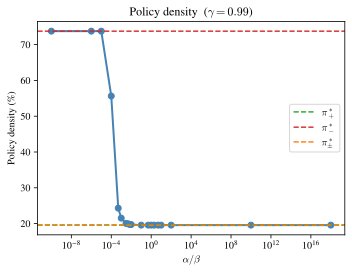

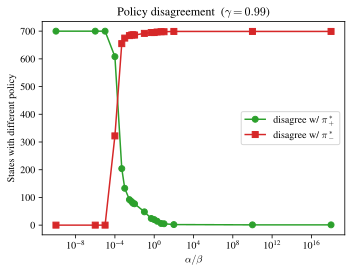

In [18]:
ratios    = [r['ratio']      for r in results]
densities = [r['density']    for r in results]
d_plus    = [r['diff_plus']  for r in results]
d_minus   = [r['diff_minus'] for r in results]

# --- Plot 1: Policy Density ---
fig, ax = plt.subplots(figsize=(5, 4))
ax.semilogx(ratios, densities, 'o-', color='steelblue', lw=2)
ax.axhline(policy_density(π_plus_gamma_99),  ls='--', color='tab:green',  lw=1.4, label=r'$\pi^*_+$')
ax.axhline(policy_density(π_minus_gamma_99), ls='--', color='tab:red',    lw=1.4, label=r'$\pi^*_-$')
ax.axhline(policy_density(π_mixed_gamma_99), ls='--', color='tab:orange', lw=1.4, label=r'$\pi^*_{\pm}$')
ax.set_xlabel(r'$\alpha / \beta$')
ax.set_ylabel('Policy density (%)')
ax.set_title(r'Policy density  ($\gamma=0.99$)')
ax.legend()
plt.tight_layout()
plt.savefig(project_dir + 'pipeline/asymmetric_reward_density.pdf', bbox_inches='tight')
plt.show()

# --- Plot 2: Policy Disagreement ---
fig, ax = plt.subplots(figsize=(5, 4))
ax.semilogx(ratios, d_plus,  'o-', color='tab:green', label=r'disagree w/ $\pi^*_+$')
ax.semilogx(ratios, d_minus, 's-', color='tab:red',   label=r'disagree w/ $\pi^*_-$')
ax.set_xlabel(r'$\alpha / \beta$')
ax.set_ylabel('States with different policy')
ax.set_title(r'Policy disagreement  ($\gamma=0.99$)')
ax.legend()
plt.tight_layout()
plt.savefig(project_dir + 'pipeline/asymmetric_reward_disagreement.pdf', bbox_inches='tight')
plt.show()

##### Summary

H1 is not confirmed. However, it is due to the existence of trap state. We exepct to see all difference with π+ to be 0, but it turns out that the disagreement with π+ grow as alpha becomes larger. Interestingly, the disagreement count is also identical when comparing it to π-. However, we found out that π+ and π- are not identical (same as former experiment), it's simply that: state 330 contributed +1 to diff(π+) and 0 to diff (π-); state 116 contributed 0 to diff(π+) and +1 to diff(π-). It's just a coincidence.

H2 is confirmed; more interestingly, the policy density decreased to π+- under gamma = 0.99. If we decrease the ratio by setting alpha to some very small number, it behaves functionally the same as π- and policy density grow back up.